# 43. Deep Neural Networks
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Depth multiplies linear pieces. Left: the tent map $t$ and its compositions $t\circ t$, $t\circ t\circ t$ and $t^{\circ4}$ (shifted upward for clarity), with $2$, $4$, $8$ and $16$ linear pieces; each composition uses two more ReLUs. Right: the number of linear pieces on an interval against the number of neurons, for a deep network built from tent maps ($2^{L}$ pieces from $2L$ neurons) and for a single hidden layer ($N+1$ pieces from $N$ neurons).

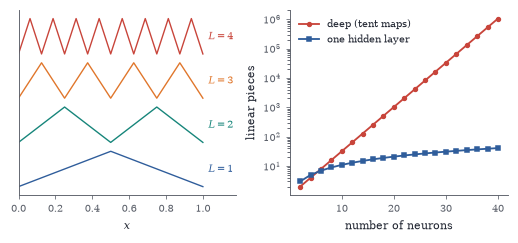

In [2]:
relu = lambda z: np.maximum(z, 0); tent = lambda x: 2 * relu(x) - 4 * relu(x - 0.5)
x = np.linspace(0, 1, 2001); fig, axs = plt.subplots(1, 2, figsize=(W, 2.1)); y = x.copy()
for L, c in zip(range(1, 5), [BLUE, TEAL, ORANGE, RED]):
    y = tent(y); axs[0].plot(x, y + 1.25 * (L - 1), color=c, lw=0.9); axs[0].text(1.03, 1.25 * (L - 1) + 0.4, f"$L={L}$", fontsize=6.5, color=c)
axs[0].set_xlim(0, 1.18); axs[0].set_yticks([]); axs[0].set_xlabel("$x$")
nn = np.arange(2, 41, 2); axs[1].semilogy(nn, 2.0 ** (nn / 2), "o-", color=RED, ms=2.5, label="deep (tent maps)"); axs[1].semilogy(nn, nn + 1, "s-", color=BLUE, ms=2.5, label="one hidden layer")
axs[1].set_xlabel("number of neurons"); axs[1].set_ylabel("linear pieces"); axs[1].legend(fontsize=6.5, frameon=False)

Linear regions of random ReLU networks on the square $[-2,2]^2$, each region (a set of inputs with the same activation pattern) in its own colour. Left: one hidden layer of $8$ neurons; the regions are the cells of an arrangement of $8$ lines, at most $r(8,2)=37$ of them. Right: two hidden layers of $8$ neurons; each second-layer neuron contributes a boundary that is bent wherever it crosses a first-layer line, so the regions are no longer the cells of any line arrangement, and their number roughly quadruples.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


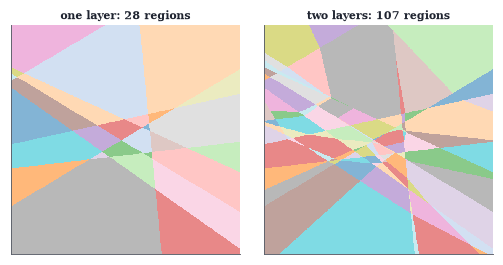

In [3]:
rng = np.random.default_rng(5); n = 600; g = np.linspace(-2, 2, n); X, Y = np.meshgrid(g, g); P = np.stack([X.ravel(), Y.ravel()], 1)
A1 = rng.normal(size=(8, 2)); b1 = rng.normal(size=8) * 0.8; A2 = rng.normal(size=(8, 8)) / np.sqrt(4); b2 = rng.normal(size=8) * 0.5
H1 = P @ A1.T + b1; pat1 = H1 > 0; H2 = np.maximum(H1, 0) @ A2.T + b2; pat2 = np.concatenate([pat1, H2 > 0], 1)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.3)); cols = plt.cm.tab20(np.linspace(0, 1, 20))
for ax, pat, title in [(axs[0], pat1, "one layer"), (axs[1], pat2, "two layers")]:
    _, ids = np.unique(pat, axis=0, return_inverse=True); ids = ids.ravel(); perm = np.random.default_rng(1).permutation(ids.max() + 1)
    img = cols[perm[ids] % 20].reshape(n, n, 4); img[..., :3] = 0.55 * img[..., :3] + 0.45
    ax.imshow(img, extent=(-2, 2, -2, 2), origin="lower", interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{title}: {ids.max() + 1} regions", fontsize=7)

In [4]:
rng = np.random.default_rng(0); sizes = [3, 5, 4, 2]; As = [rng.normal(size=(sizes[i + 1], sizes[i])) for i in range(3)]; bs = [rng.normal(size=sizes[i + 1]) for i in range(3)]
v0 = rng.normal(size=3); yt = np.array([1.0, -1.0]); relu = lambda z: np.maximum(z, 0)
def loss(As, bs):
    v = v0
    for l in range(3): z = As[l] @ v + bs[l]; v = relu(z) if l < 2 else z
    return 0.5 * np.sum((v - yt) ** 2)
vs, zs, v = [v0], [], v0
for l in range(3): z = As[l] @ v + bs[l]; zs.append(z); v = relu(z) if l < 2 else z; vs.append(v)
d = vs[-1] - yt; grads = [None] * 3
for l in (2, 1, 0):
    grads[l] = np.outer(d, vs[l])
    if l > 0: d = (zs[l - 1] > 0) * (As[l].T @ d)
h = 1e-6; i, j = np.unravel_index(np.argmax(np.abs(grads[1])), grads[1].shape); Ap = [A.copy() for A in As]; Am = [A.copy() for A in As]; Ap[1][i, j] += h; Am[1][i, j] -= h
print(f"backprop dL/dA2[{i},{j}] =", round(grads[1][i, j], 8), "   finite difference =", round((loss(Ap, bs) - loss(Am, bs)) / (2 * h), 8))

backprop dL/dA2[2,4] = 31.5886056    finite difference = 31.58860559


Signal propagation in deep networks of width $N=128$. Left: squared activation norm (relative to the input) through $60$ ReLU layers initialized with variance $c^2\cdot\frac2n$, for $c=0.9$, $1$, $1.1$; only He's scale ($c=1$) keeps the signal at a constant level, the others decay or explode geometrically. Right: singular values of the product of $L=40$ matrices of size $128$: Gaussian matrices with variance $\frac1N$ spread over many orders of magnitude, while residual products $\prod(I+G_\ell/\sqrt{NL})$ stay within a narrow band around $1$; orthogonal products have every singular value exactly $1$ (dashed).

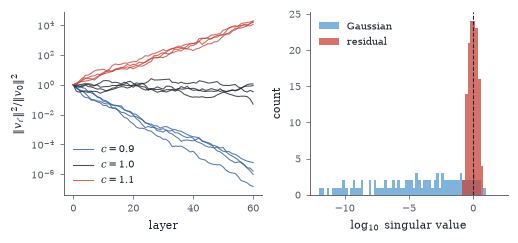

In [5]:
rng = np.random.default_rng(2); N = 128; Ld = 60; v0 = rng.normal(size=N); fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for c, col in [(0.9, BLUE), (1.0, INK), (1.1, RED)]:
    for rep in range(4):
        v = v0.copy(); nr = [1.0]
        for l in range(Ld): v = np.maximum(rng.normal(size=(N, N)) * c * np.sqrt(2 / N) @ v, 0); nr.append(np.sum(v**2) / np.sum(v0**2))
        axs[0].semilogy(nr, color=col, lw=0.7, alpha=0.8, label=f"$c={c}$" if rep == 0 else None)
axs[0].set_xlabel("layer"); axs[0].set_ylabel(r"$\|v_\ell\|^2/\|v_0\|^2$"); axs[0].legend(fontsize=6.5, frameon=False, loc="lower left")
L = 40; Pg = np.eye(N); Pr = np.eye(N)
for l in range(L): Pg = rng.normal(size=(N, N)) / np.sqrt(N) @ Pg; Pr = (np.eye(N) + rng.normal(size=(N, N)) / np.sqrt(N * L)) @ Pr
bins = np.linspace(-12, 2, 70); axs[1].hist(np.log10(np.linalg.svd(Pg, compute_uv=False)), bins=bins, color=SKY, alpha=0.85, label="Gaussian")
axs[1].hist(np.log10(np.linalg.svd(Pr, compute_uv=False)), bins=bins, color=RED, alpha=0.75, label="residual"); axs[1].axvline(0, color=INK, ls="--", lw=0.7)
axs[1].set_xlabel(r"$\log_{10}$ singular value"); axs[1].set_ylabel("count"); axs[1].legend(fontsize=6.5, frameon=False, loc="upper left")

Classical $3\times3$ filters applied to a synthetic image (a disc, a tilted square and a smooth ramp). From left: the image; binomial blur; Sobel $S_x$ (vertical edges, signed); Sobel $S_y$ (horizontal edges); the discrete Laplacian, which vanishes on the ramp and outlines every edge with a positive–negative pair.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


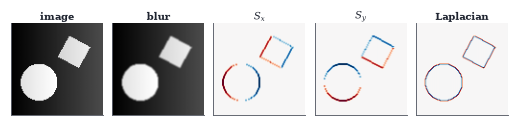

In [6]:
from scipy.signal import correlate2d
n = 96; yy, xx = np.mgrid[0:n, 0:n] / n; img = 0.35 * xx + ((xx - 0.3) ** 2 + (yy - 0.35) ** 2 < 0.04)
R = np.array([[np.cos(0.5), -np.sin(0.5)], [np.sin(0.5), np.cos(0.5)]]); uv = np.einsum("ij,jkl->ikl", R, np.stack([xx - 0.68, yy - 0.68])); img = img + 0.8 * ((np.abs(uv[0]) < 0.13) & (np.abs(uv[1]) < 0.13))
blur = np.outer([1, 2, 1], [1, 2, 1]) / 16; Sx = np.outer([1, 2, 1], [-1, 0, 1]); Lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
outs = [img, correlate2d(img, blur, mode="same", boundary="symm"), correlate2d(img, Sx, mode="same", boundary="symm"), correlate2d(img, Sx.T, mode="same", boundary="symm"), correlate2d(img, Lap, mode="same", boundary="symm")]
fig, axs = plt.subplots(1, 5, figsize=(W, 1.05))
for k, (ax, o) in enumerate(zip(axs, outs)):
    if k < 2: ax.imshow(o, cmap="gray", origin="lower")
    else: m = np.abs(o).max(); ax.imshow(o, cmap=CMAP, vmin=-m, vmax=m, origin="lower")
    ax.set_xticks([]); ax.set_yticks([])
for ax, t in zip(axs, ["image", "blur", r"$S_x$", r"$S_y$", "Laplacian"]): ax.set_title(t, fontsize=6.5, pad=2)

Eigenvalues (sorted, log scale) of the Gauss–Newton matrix of a linear softmax classifier with $K=4$ classes in $d=30$ dimensions, data drawn from four Gaussian clusters. At initialization (blue) the matrix is the Kronecker product $F_0\otimes S$ of [@prop-gn-kronecker], and exactly $K(K-1)=12$ outliers stand above a bulk, followed by $d=30$ zeros (not shown). After $100$ steps of gradient descent (red) the whole spectrum has shrunk, since confidently classified examples contribute little curvature, and the top few eigenvalues still stand apart from the rest.

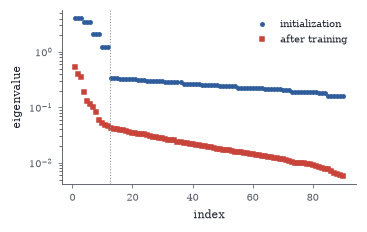

In [7]:
rng = np.random.default_rng(0); K, d, n = 4, 30, 600; Mu = rng.normal(size=(K, d)) * 1.2; yl = rng.integers(K, size=n); X = Mu[yl] + rng.normal(size=(n, d)); Yh = np.eye(K)[yl]
def gn(Wm):
    Z = X @ Wm.T; Pm = np.exp(Z - Z.max(1, keepdims=True)); Pm /= Pm.sum(1, keepdims=True); G = np.zeros((K * d, K * d))
    for i in range(n): G += np.kron(np.diag(Pm[i]) - np.outer(Pm[i], Pm[i]), np.outer(X[i], X[i])) / n
    return np.sort(np.linalg.eigvalsh(G))[::-1], Pm
Wm = np.zeros((K, d)); e0, _ = gn(Wm)
for t in range(100):
    Z = X @ Wm.T; Pm = np.exp(Z - Z.max(1, keepdims=True)); Pm /= Pm.sum(1, keepdims=True); Wm -= 0.05 * (Pm - Yh).T @ X / n
e1, _ = gn(Wm); k = np.arange(1, K * d + 1)
fig, ax = plt.subplots(figsize=(W * 0.7, 2.0)); ax.semilogy(k[: K * d - d], e0[: K * d - d], "o", color=BLUE, ms=2.2, label="initialization"); ax.semilogy(k[: K * d - d], np.maximum(e1[: K * d - d], 1e-8), "s", color=RED, ms=2.2, label="after training")
ax.axvline(K * (K - 1) + 0.5, color=GRAY, ls=":", lw=0.7); ax.set_xlabel("index"); ax.set_ylabel("eigenvalue"); ax.legend(fontsize=6.5, frameon=False)

Early stopping as spectral filtering. Filter factors applied to the component of the least squares solution along a singular direction with singular value $\sigma$: gradient descent stopped after $k$ steps ($1-(1-\eta\sigma^2)^k$, solid) and ridge regression with $\lambda=1/(\eta k)$ ($\sigma^2/(\sigma^2+\lambda)$, dashed), for $\eta=1$ and $k=10,100,1000$. Both pass the large singular directions and suppress the small ones, with the cutoff at $\sigma^2\approx1/(\eta k)$ moving down as training continues.

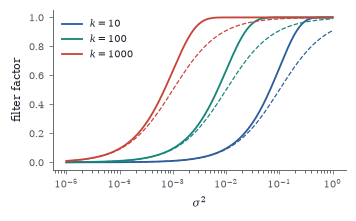

In [8]:
s2 = np.geomspace(1e-5, 1, 400); fig, ax = plt.subplots(figsize=(W * 0.68, 1.9))
for kk, c in [(10, BLUE), (100, TEAL), (1000, RED)]:
    ax.semilogx(s2, 1 - (1 - s2) ** kk, color=c, label=f"$k={kk}$"); ax.semilogx(s2, s2 / (s2 + 1 / kk), "--", color=c, lw=0.8)
ax.set_xlabel(r"$\sigma^2$"); ax.set_ylabel("filter factor"); ax.legend(fontsize=6.5, frameon=False, loc="upper left")

In [9]:
rng = np.random.default_rng(0); P = rng.normal(size=(400000, 3)); S = np.c_[P > 0, P.sum(1) > 0]
print("activation patterns found:", len(np.unique(S, axis=0)))

activation patterns found: 14


In [10]:
def mlp_train(X, y, widths, steps=3000, lr=0.02, seed=0):
    rng = np.random.default_rng(seed); sz = [X.shape[1]] + list(widths) + [1]; P = []
    for a, b in zip(sz[:-1], sz[1:]): P += [rng.normal(size=(b, a)) * np.sqrt(2 / a), np.zeros(b)]
    m = [np.zeros_like(p) for p in P]; v = [np.zeros_like(p) for p in P]
    for t in range(1, steps + 1):
        hs, zs = [X.T], []
        for l in range(len(sz) - 1):
            z = P[2 * l] @ hs[-1] + P[2 * l + 1][:, None]; zs.append(z); hs.append(np.maximum(z, 0) if l < len(sz) - 2 else z)
        d = ((1 / (1 + np.exp(-hs[-1][0])) - y) / len(y))[None, :]; G = [None] * len(P)
        for l in range(len(sz) - 2, -1, -1):
            G[2 * l] = d @ hs[l].T; G[2 * l + 1] = d.sum(1)
            if l > 0: d = (zs[l - 1] > 0) * (P[2 * l].T @ d)
        for i in range(len(P)):
            m[i] = 0.9 * m[i] + 0.1 * G[i]; v[i] = 0.999 * v[i] + 0.001 * G[i] ** 2
            P[i] -= lr * (m[i] / (1 - 0.9**t)) / (np.sqrt(v[i] / (1 - 0.999**t)) + 1e-8)
    return P
def mlp_out(P, X):
    h = X.T; L = len(P) // 2
    for l in range(L): z = P[2 * l] @ h + P[2 * l + 1][:, None]; h = np.maximum(z, 0) if l < L - 1 else z
    return h[0]
rng = np.random.default_rng(1); n = 200
r = np.r_[rng.uniform(0, 1, n), rng.uniform(1.5, 2.5, n)]; th = rng.uniform(0, 2 * np.pi, 2 * n); Xr = np.c_[r * np.cos(th), r * np.sin(th)]; yr = np.r_[np.ones(n), np.zeros(n)]
tt = np.sqrt(rng.uniform(0, 1, n)) * 3 * np.pi; Xs = np.r_[np.c_[tt * np.cos(tt), tt * np.sin(tt)], np.c_[-tt * np.cos(tt), -tt * np.sin(tt)]] / (3 * np.pi) * 2 + rng.normal(size=(2 * n, 2)) * 0.03; ys = np.r_[np.ones(n), np.zeros(n)]
acc = lambda P, X, y: float(((mlp_out(P, X) > 0) == y).mean())
print("data sets ready: ring", Xr.shape, " spirals", Xs.shape)

data sets ready: ring (400, 2)  spirals (400, 2)


In [11]:
for N in (2, 3, 4, 6):
    print(f"N={N}:  r(N,2)={1 + N + N * (N - 1) // 2:2d} pieces   training accuracy over 5 runs:", [round(acc(mlp_train(Xr, yr, [N], seed=s), Xr, yr), 3) for s in range(5)])

N=2:  r(N,2)= 4 pieces   training accuracy over 5 runs: [0.84, 0.705, 0.703, 0.84, 0.83]


N=3:  r(N,2)= 7 pieces   training accuracy over 5 runs: [0.662, 1.0, 1.0, 1.0, 1.0]


N=4:  r(N,2)=11 pieces   training accuracy over 5 runs: [1.0, 1.0, 1.0, 1.0, 1.0]


N=6:  r(N,2)=22 pieces   training accuracy over 5 runs: [1.0, 1.0, 1.0, 1.0, 1.0]


In [12]:
for w in ([8], [32], [6, 2], [2, 6], [8, 8]):
    print(f"{str(w):8s}", [round(acc(mlp_train(Xs, ys, w, steps=4000, lr=0.01, seed=s), Xs, ys), 3) for s in range(3)])

[8]      [0.922, 0.963, 0.973]


[32]     [1.0, 1.0, 1.0]


[6, 2]   [0.855, 0.922, 0.785]


[2, 6]   [0.752, 0.723, 0.81]


[8, 8]   [1.0, 1.0, 1.0]


Decision regions of trained ReLU networks (blue: positive output). From left: disc and ring with one hidden layer of $2$, $3$ and $4$ neurons (two folds cannot enclose the disc; three and four neurons enclose it in a polygon), and the two spirals with one hidden layer of $8$ neurons and with two hidden layers of $8+8$. All boundaries are polygonal, as for any ReLU network.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


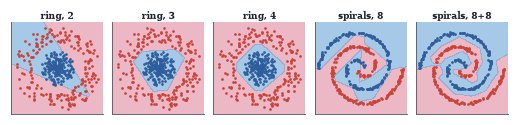

In [13]:
gx = np.linspace(-2.8, 2.8, 220); GX, GY = np.meshgrid(gx, gx); grid = np.c_[GX.ravel(), GY.ravel()]
cases = [(Xr, yr, [2], 3000, 0.02, "ring, 2"), (Xr, yr, [3], 3000, 0.02, "ring, 3"), (Xr, yr, [4], 3000, 0.02, "ring, 4"), (Xs, ys, [8], 4000, 0.01, "spirals, 8"), (Xs, ys, [8, 8], 4000, 0.01, "spirals, 8+8")]
fig, axs = plt.subplots(1, 5, figsize=(W, 1.15))
for ax, (X_, y_, w, st, lr, t) in zip(axs, cases):
    best = max((mlp_train(X_, y_, w, steps=st, lr=lr, seed=s) for s in range(3)), key=lambda P: acc(P, X_, y_))
    Z = (mlp_out(best, grid) > 0).reshape(GX.shape); ax.contourf(GX, GY, Z, levels=[-0.5, 0.5, 1.5], colors=[ROSE, SKY], alpha=0.6)
    ax.scatter(X_[y_ == 1, 0], X_[y_ == 1, 1], s=0.6, color=BLUE); ax.scatter(X_[y_ == 0, 0], X_[y_ == 0, 1], s=0.6, color=RED)
    lim = 2.7 if X_ is Xr else 2.2; ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t, fontsize=6, pad=2)

In [14]:
rng = np.random.default_rng(3); Xq = rng.uniform(-1, 1, (400, 2)); Xq = Xq[np.abs(Xq).min(1) > 0.15]; yq = (Xq[:, 0] * Xq[:, 1] > 0).astype(float)
for N in (2, 3, 4): print(f"N={N}:", [round(acc(mlp_train(Xq, yq, [N], seed=s), Xq, yq), 3) for s in range(5)])

N=2: [0.748, 0.929, 0.745, 0.711, 0.748]


N=3: [0.748, 1.0, 1.0, 0.748, 0.748]


N=4: [1.0, 0.748, 1.0, 1.0, 1.0]


In [15]:
from scipy.signal import correlate2d
b3 = np.outer([1, 2, 1], [1, 2, 1]) / 16; b5 = np.outer([1, 4, 6, 4, 1], [1, 4, 6, 4, 1]) / 256
H = np.r_[np.ones((4, 8)), np.zeros((4, 8))]; D = np.tril(np.ones((8, 8)))
for name, E in [("horizontal", H), ("diagonal", D)]:
    print(name, "edge, middle column after 3x3:", np.round(correlate2d(E, b3, mode="same", boundary="symm")[:, 4], 3))
    print(name, "edge, middle column after 5x5:", np.round(correlate2d(E, b5, mode="same", boundary="symm")[:, 4], 3))

horizontal edge, middle column after 3x3: [1.   1.   1.   0.75 0.25 0.   0.   0.  ]
horizontal edge, middle column after 5x5: [1.    1.    0.938 0.688 0.312 0.062 0.    0.   ]
diagonal edge, middle column after 3x3: [0.    0.    0.062 0.312 0.688 0.938 1.    1.   ]
diagonal edge, middle column after 5x5: [0.004 0.035 0.145 0.363 0.637 0.855 0.965 0.996]


In [16]:
T = np.diag([-2.0] * 3) + np.diag([1.0] * 2, 1) + np.diag([1.0] * 2, -1); M = np.kron(T, np.eye(3)) + np.kron(np.eye(3), T)
Vimg = np.arange(1, 10).reshape(3, 3).astype(float); from scipy.signal import correlate2d
print("matrix times vec(V):", M @ Vimg.ravel()); print("correlation:       ", correlate2d(Vimg, np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]), mode="same").ravel())

matrix times vec(V): [  2.   1.  -4.  -3.   0.  -7. -16. -11. -22.]
correlation:        [  2.   1.  -4.  -3.   0.  -7. -16. -11. -22.]


In [17]:
L5 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]); L9 = np.array([[1, 4, 1], [4, -20, 4], [1, 4, 1]])
V = np.r_[[[2] * 3 + [6] * 3] * 4].astype(float); Dg = 2 + 4 * np.tril(np.ones((6, 6)), -1)
for name, E in [("vertical", V), ("diagonal", Dg)]:
    print(name, "edge, row 2, five-point:", correlate2d(E, L5, mode="valid")[1], "  nine-point / 6:", np.round(correlate2d(E, L9, mode="valid")[1] / 6, 3))

vertical edge, row 2, five-point: [ 0.  4. -4.  0.]   nine-point / 6: [ 0.  4. -4.  0.]
diagonal edge, row 2, five-point: [-8.  8.  0.  0.]   nine-point / 6: [-6.     6.     0.667  0.   ]


In [18]:
F45 = np.outer([1, 2, 1], [-1, 0, 1]) + np.outer([-1, 0, 1], [1, 2, 1]); i, j = np.mgrid[0:7, 0:7]
print("edge along (1,1):", correlate2d((i - j > 0).astype(float), F45, mode="valid")[2]); print("edge along (1,-1):", correlate2d((i + j > 6).astype(float), F45, mode="valid")[2])

edge along (1,1): [0. 0. 0. 0. 0.]
edge along (1,-1): [0. 2. 6. 6. 2.]


In [19]:
rng = np.random.default_rng(4); A = rng.normal(size=(4, 4)) + 4 * np.eye(4); b = rng.normal(size=4); x = np.linalg.solve(A, b); h = 1e-7; i, j, k = 0, 2, 3
Ah = A.copy(); Ah[j, k] += h; print("formula:", -np.linalg.inv(A)[i, j] * x[k], "  finite difference:", (np.linalg.solve(Ah, b)[i] - x[i]) / h)

formula: -0.016926623888302367   finite difference: -0.016926623436219757
